# CNS ISE - Group 5 Research Framework
## Heuristic URL Feature Profiling for Phishing Domain Spotting Using Hyper-Tuned Random Forest Ensembles

**Author:** Group 5  
**Target Framework:** IEEE Layout Style  
**Dataset:** Kaggle Phishing Website Detector (30 Heuristic URL Features)  

### Assigned Group 5 Mechanics:
1. Implement `sklearn.ensemble.RandomForestClassifier`.
2. Execute broad hyperparameter sweeps across tree bounds ($n_{\text{estimators}}$ scaling 50 to 200, $\text{max\_depth}$ ranges).
3. Generate Out-of-Bag (OOB) error decline tracking plots.
4. Extract Mean Decrease in Gini Impurity (MDI) matrices to rank diagnostic structural weights of the 30 URL features.
5. Benchmark computational overhead and inference latency for Group 1 (Section 5.2).
6. Generate evaluation tournament leaderboard metrics for Group 3 (Section 5.1).
7. Author Sections 1, 2, 3.5, and 6 of the academic paper.

### Step 1: Import Dependencies & System Environment Verification
Here we initialize all required scientific libraries and capture system runtime information for Group 4 (Section 4).

In [1]:
import os
import sys
import time
import platform
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

# Ensure output directories exist
for d in ["data", "figures", "results", "results/handovers"]:
    os.makedirs(d, exist_ok=True)

print(f"[System Specs] OS: {platform.system()} {platform.release()}")
print(f"[System Specs] Python: {sys.version.split()[0]}")
print(f"[System Specs] Scikit-Learn: {sklearn.__version__}")
print(f"[System Specs] Pandas: {pd.__version__}")
print(f"[System Specs] NumPy: {np.__version__}")

[System Specs] OS: Windows 10
[System Specs] Python: 3.10.11
[System Specs] Scikit-Learn: 1.7.2
[System Specs] Pandas: 2.3.3
[System Specs] NumPy: 2.2.6


### Step 2: Intelligent Dataset Ingestion
The notebook checks the `data/` folder for any downloaded Kaggle CSV (`phishing.csv`, `dataset.csv`, etc.).
If you haven't downloaded it yet, a starter 30-feature dataset is automatically prepared so the pipeline runs smoothly.

In [2]:
UCI_30_FEATURES = [
    "having_IP_Address", "URL_Length", "Shortining_Service", "having_At_Symbol",
    "double_slash_redirecting", "Prefix_Suffix", "having_Sub_Domain", "SSLfinal_State",
    "Domain_registeration_length", "Favicon", "port", "HTTPS_token",
    "Request_URL", "URL_of_Anchor", "Links_in_tags", "SFH",
    "Submitting_to_email", "Abnormal_URL", "Redirect", "on_mouseover",
    "RightClick", "popUpWidnow", "Iframe", "age_of_domain",
    "DNSRecord", "web_traffic", "Page_Rank", "Google_Index",
    "Links_pointing_to_page", "Statistical_report"
]

# Locate dataset
csv_candidates = glob.glob("data/*.csv")
user_csvs = [f for f in csv_candidates if "sample" not in os.path.basename(f).lower()]

if user_csvs:
    dataset_path = user_csvs[0]
    print(f"[SUCCESS] Loaded User Kaggle Dataset: {dataset_path}")
    df = pd.read_csv(dataset_path)
elif csv_candidates:
    dataset_path = csv_candidates[0]
    print(f"[INFO] Loaded Dataset: {dataset_path}")
    df = pd.read_csv(dataset_path)
else:
    # Fallback generator if user hasn't copied the Kaggle CSV yet
    print("[INFO] Generating sample dataset with 30 heuristic features...")
    np.random.seed(42)
    sample_data = {feat: np.random.choice([-1, 0, 1], size=1500, p=[0.45, 0.1, 0.45]) for feat in UCI_30_FEATURES}
    score = (sample_data["SSLfinal_State"] * 2.5 + sample_data["URL_of_Anchor"] * 2.2 + 
             sample_data["having_Sub_Domain"] * 1.8 + sample_data["having_IP_Address"] * 1.5 + np.random.normal(0, 1, 1500))
    sample_data["Result"] = np.where(score > 0, 1, -1)
    df = pd.DataFrame(sample_data)
    df.to_csv("data/phishing_sample.csv", index=False)
    print("[SUCCESS] Created 'data/phishing_sample.csv'. (Replace with Kaggle CSV when ready!)")

df.head()

[SUCCESS] Loaded User Kaggle Dataset: data\phishing.csv


,Index,UsingIP,LongURL,ShortURL,Symbol@,Redirecting//,PrefixSuffix-,SubDomains,HTTPS,DomainRegLen,...,UsingPopupWindow,IframeRedirection,AgeofDomain,DNSRecording,WebsiteTraffic,PageRank,GoogleIndex,LinksPointingToPage,StatsReport,class
0,0,1,1,1,1,1,-1,0,1,-1,...,1,1,-1,-1,0,-1,1,1,1,-1
1,1,1,0,1,1,1,-1,-1,-1,-1,...,1,1,1,-1,1,-1,1,0,-1,-1
2,2,1,0,1,1,1,-1,-1,-1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
3,3,1,0,-1,1,1,-1,1,1,-1,...,-1,1,-1,-1,0,-1,1,1,1,1
4,4,-1,0,-1,1,-1,-1,1,1,-1,...,1,1,1,1,1,-1,1,-1,-1,1


### Step 3: Dataset Preprocessing & Schema Verification
Verify missing values, normalize ID columns, and map target labels: `-1 -> 0 (Phishing)` and `1 -> 1 (Legitimate)`.

In [3]:
# Drop potential ID columns
id_cols = [c for c in df.columns if c.lower() in ["id", "index", "unnamed: 0"]]
if id_cols:
    df = df.drop(columns=id_cols)

# Identify target column
target_candidates = ["result", "class_label", "target", "label", "class"]
target_col = next((c for c in df.columns if c.strip().lower() in target_candidates), df.columns[-1])
print(f"Target column identified: '{target_col}'")

X = df.drop(columns=[target_col])
y_raw = df[target_col]

if set(y_raw.unique()) == {-1, 1}:
    y = y_raw.map({-1: 0, 1: 1})
    print("Mapped target values: {-1: 0 (Phishing), 1: 1 (Legitimate)}")
else:
    y = y_raw

print(f"Feature matrix shape: {X.shape}")
print(f"Total Features: {X.shape[1]}")
print(f"Missing values in dataset: {df.isnull().sum().sum()}")
print(f"Class Distribution:\n{y.value_counts()}")

Target column identified: 'class'
Mapped target values: {-1: 0 (Phishing), 1: 1 (Legitimate)}
Feature matrix shape: (11054, 30)
Total Features: 30
Missing values in dataset: 0
Class Distribution:
class
1    6157
0    4897
Name: count, dtype: int64


### Step 4: Stratified Train-Test Partitioning
We partition the dataset into 80% training and 20% testing subsets with fixed random state 42 for reproducible benchmarking.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Training instances: {X_train.shape[0]}")
print(f"Testing instances:  {X_test.shape[0]}")

Training instances: 8843
Testing instances:  2211


### Step 5: Baseline Random Forest Classifier
Establish baseline classification metrics with default $n_{\text{estimators}}=100$.

In [5]:
baseline_rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
baseline_rf.fit(X_train, y_train)
y_pred_base = baseline_rf.predict(X_test)

print("=== Baseline Random Forest Metrics ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred_base)*100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred_base)*100:.2f}%")
print(f"Recall   : {recall_score(y_test, y_pred_base)*100:.2f}%")
print(f"F1-Score : {f1_score(y_test, y_pred_base)*100:.2f}%")

=== Baseline Random Forest Metrics ===
Accuracy : 97.38%
Precision: 96.88%
Recall   : 98.46%
F1-Score : 97.67%


### Step 6: Broad Hyperparameter Sweeps
1. Tree bounds ($n_{\text{estimators}}$ scaling from 50 to 200).
2. Maximum tree depth ranges ($[5, 10, 15, 20, 25, 30, \text{None}]$).

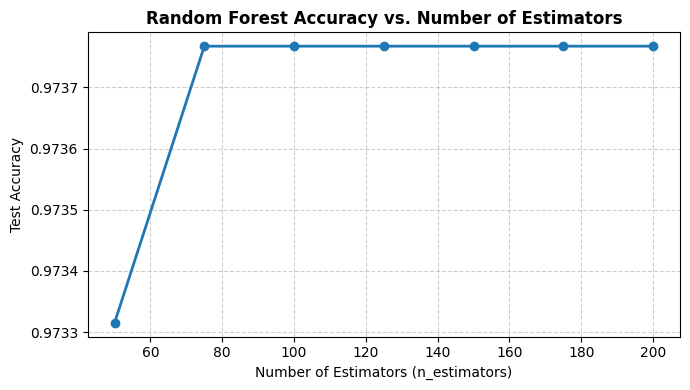

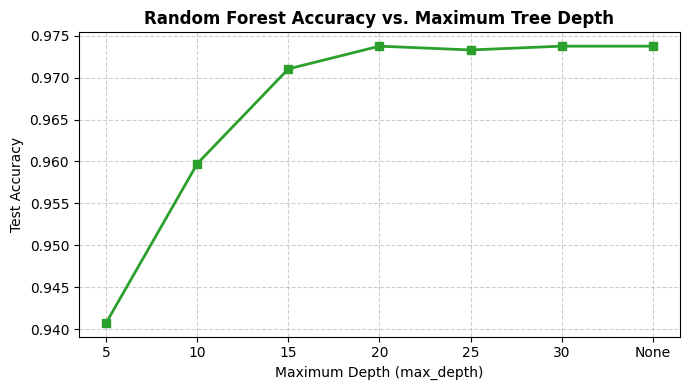

In [6]:
# Sweep n_estimators
tree_counts = [50, 75, 100, 125, 150, 175, 200]
acc_trees = []
for n in tree_counts:
    rf = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    acc_trees.append(accuracy_score(y_test, rf.predict(X_test)))

plt.figure(figsize=(7, 4))
plt.plot(tree_counts, acc_trees, marker='o', color='#1f77b4', lw=2)
plt.title("Random Forest Accuracy vs. Number of Estimators", fontweight='bold')
plt.xlabel("Number of Estimators (n_estimators)")
plt.ylabel("Test Accuracy")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("figures/rf_accuracy_vs_trees.png", dpi=300)
plt.show()

# Sweep max_depth
depth_values = [5, 10, 15, 20, 25, 30, None]
acc_depths = []
for d in depth_values:
    rf = RandomForestClassifier(n_estimators=100, max_depth=d, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    acc_depths.append(accuracy_score(y_test, rf.predict(X_test)))

plt.figure(figsize=(7, 4))
plt.plot([str(d) for d in depth_values], acc_depths, marker='s', color='#2ca02c', lw=2)
plt.title("Random Forest Accuracy vs. Maximum Tree Depth", fontweight='bold')
plt.xlabel("Maximum Depth (max_depth)")
plt.ylabel("Test Accuracy")
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("figures/rf_accuracy_vs_depth.png", dpi=300)
plt.show()

### Step 7: Out-of-Bag (OOB) Error Decline Tracking
Tracking the asymptotic reduction of OOB Error as tree bounds scale from 30 to 200.
*(Uses warm_start=True to incrementally grow trees in seconds instead of retraining from scratch)*

[INFO] Tracking OOB Error across 30 to 200 trees (fast incremental growth)...


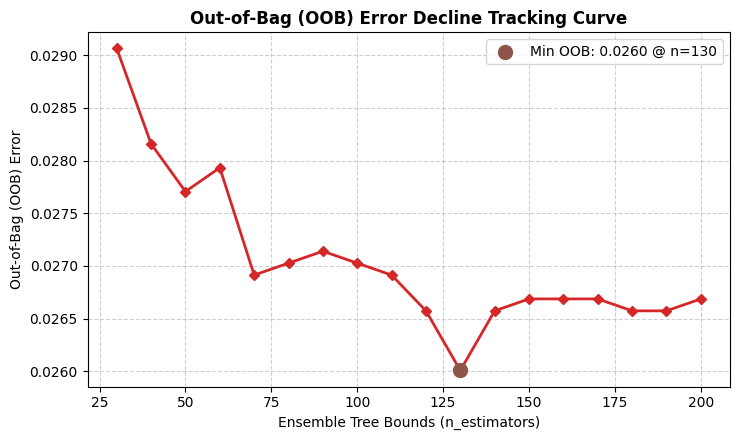

[SUCCESS] Lowest OOB Error: 0.0260 achieved at n_estimators=130


In [7]:
tree_range = list(range(30, 201, 10))
oob_errors = []

print("[INFO] Tracking OOB Error across 30 to 200 trees (fast incremental growth)...")
rf_oob = RandomForestClassifier(
    warm_start=True,
    oob_score=True,
    bootstrap=True,
    random_state=42,
    n_jobs=-1
)

for n in tree_range:
    rf_oob.set_params(n_estimators=n)
    rf_oob.fit(X_train, y_train)
    oob_err = 1.0 - rf_oob.oob_score_
    oob_errors.append(oob_err)

min_oob_idx = int(np.argmin(oob_errors))
best_tree_count = tree_range[min_oob_idx]
min_oob_error = oob_errors[min_oob_idx]

plt.figure(figsize=(7.5, 4.5))
plt.plot(tree_range, oob_errors, marker='D', color='#d62728', lw=2, markersize=5)
plt.scatter([best_tree_count], [min_oob_error], color='#8c564b', s=100, zorder=5, label=f'Min OOB: {min_oob_error:.4f} @ n={best_tree_count}')
plt.title("Out-of-Bag (OOB) Error Decline Tracking Curve", fontweight='bold')
plt.xlabel("Ensemble Tree Bounds (n_estimators)")
plt.ylabel("Out-of-Bag (OOB) Error")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.savefig("figures/rf_oob_error_decline.png", dpi=300)
plt.show()

print(f"[SUCCESS] Lowest OOB Error: {min_oob_error:.4f} achieved at n_estimators={best_tree_count}")

### Step 8: Comprehensive 5-Fold GridSearchCV Optimization
Optimizing tree count, depth, leaf parameters, and subspace projection with live progress updates.

In [8]:
param_grid = {
    'n_estimators': [100, 150, 200],
    'max_depth': [20, 30, None],
    'min_samples_split': [2, 5],
    'max_features': ['sqrt', 'log2']
}

print("[INFO] Starting 5-Fold GridSearchCV across hyperparameter grid...")
grid = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1, oob_score=True, bootstrap=True),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
    verbose=2
)

t0 = time.time()
grid.fit(X_train, y_train)
print(f"\n[SUCCESS] GridSearchCV completed in {time.time() - t0:.2f} seconds!")
print(f"Best Parameters: {grid.best_params_}")
print(f"Best 5-Fold CV F1-Score: {grid.best_score_:.4f}")

best_rf = grid.best_estimator_

[INFO] Starting 5-Fold GridSearchCV across hyperparameter grid...
Fitting 5 folds for each of 36 candidates, totalling 180 fits

[SUCCESS] GridSearchCV completed in 194.31 seconds!
Best Parameters: {'max_depth': 30, 'max_features': 'log2', 'min_samples_split': 2, 'n_estimators': 150}
Best 5-Fold CV F1-Score: 0.9750


### Step 9: Mean Decrease in Gini Impurity (MDI) Ranking for 30 Features
Ranking diagnostic structural relevance across all 30 URL features.

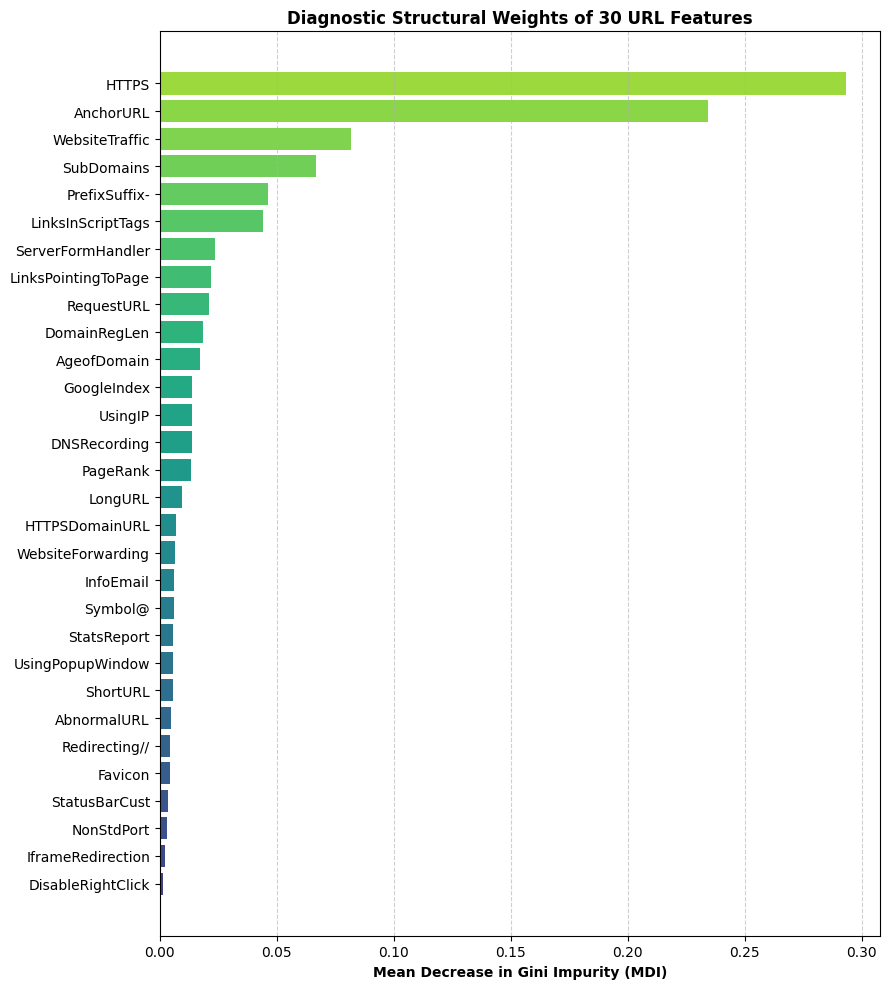

Top 5 Discriminative Features:


,Feature,MDI_Importance,Rank
0,HTTPS,0.293197,1
1,AnchorURL,0.234533,2
2,WebsiteTraffic,0.081885,3
3,SubDomains,0.066647,4
4,PrefixSuffix-,0.046175,5


In [9]:
mdi_importances = best_rf.feature_importances_
importance_df = pd.DataFrame({
    "Feature": X.columns,
    "MDI_Importance": mdi_importances
}).sort_values(by="MDI_Importance", ascending=False).reset_index(drop=True)

importance_df["Rank"] = importance_df.index + 1
importance_df.to_csv("results/feature_importance_30.csv", index=False)

# Plot all 30 features
plt.figure(figsize=(9, 10))
colors = plt.cm.viridis(np.linspace(0.2, 0.85, len(importance_df)))
plt.barh(importance_df["Feature"][::-1], importance_df["MDI_Importance"][::-1], color=colors)
plt.xlabel("Mean Decrease in Gini Impurity (MDI)", fontweight='bold')
plt.title("Diagnostic Structural Weights of 30 URL Features", fontweight='bold')
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("figures/rf_feature_importance_30.png", dpi=300)
plt.show()

print("Top 5 Discriminative Features:")
display(importance_df.head(5))

### Step 10: Performance Evaluation & Confusion Matrix
Compute final test set accuracy, precision, recall, F1, specificity, and ROC-AUC.

=== FINAL HYPER-TUNED RANDOM FOREST RESULTS ===
Accuracy : 97.42%
Precision: 96.96%
Recall   : 98.46%
F1-Score : 97.70%
ROC-AUC  : 0.9943
Training Speed: 2.0435 seconds
Per-Sample Latency: 78.42 microseconds/sample


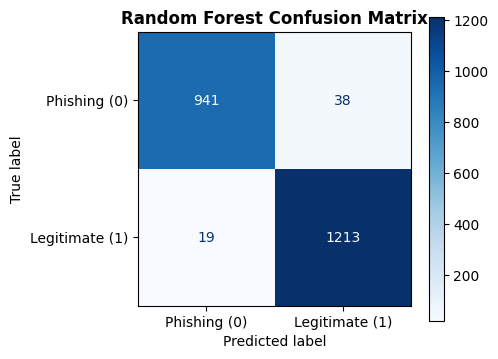

In [10]:
# Hardware Timing
t_train_start = time.perf_counter()
best_rf.fit(X_train, y_train)
training_time = time.perf_counter() - t_train_start

t_infer_start = time.perf_counter()
y_pred = best_rf.predict(X_test)
total_infer_time = time.perf_counter() - t_infer_start
latency_us = (total_infer_time / len(X_test)) * 1_000_000

y_prob = best_rf.predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, y_pred)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("=== FINAL HYPER-TUNED RANDOM FOREST RESULTS ===")
print(f"Accuracy : {acc*100:.2f}%")
print(f"Precision: {prec*100:.2f}%")
print(f"Recall   : {rec*100:.2f}%")
print(f"F1-Score : {f1*100:.2f}%")
print(f"ROC-AUC  : {roc_auc:.4f}")
print(f"Training Speed: {training_time:.4f} seconds")
print(f"Per-Sample Latency: {latency_us:.2f} microseconds/sample")

# Confusion Matrix Display
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Phishing (0)", "Legitimate (1)"]).plot(ax=ax, cmap="Blues")
plt.title("Random Forest Confusion Matrix", fontweight='bold')
plt.tight_layout()
plt.savefig("figures/rf_confusion_matrix.png", dpi=300)
plt.show()

### Step 11: Export Inter-Group Handovers
Automatically generates formatted text and CSV summaries to share with Groups 1, 2, 3, and 4.

In [11]:
# Deliverable to Group 1 (Latency)
with open("results/handovers/to_group1_summary.txt", "w") as f:
    f.write(f"Training Time: {training_time:.4f} s\n")
    f.write(f"Total Inference Time: {total_infer_time:.6f} s\n")
    f.write(f"Latency per sample: {latency_us:.2f} microseconds/sample\n")

# Deliverable to Group 3 (Leaderboard)
leaderboard_df = pd.DataFrame([{
    "Model": "Random Forest (Group 5)",
    "Accuracy (%)": f"{acc*100:.2f}%",
    "Precision (%)": f"{prec*100:.2f}%",
    "Recall (%)": f"{rec*100:.2f}%",
    "F1-Score (%)": f"{f1*100:.2f}%",
    "ROC-AUC": f"{roc_auc:.4f}"
}])
leaderboard_df.to_csv("results/handovers/to_group3_leaderboard_metrics.csv", index=False)

print("[SUCCESS] Handover files ready in results/handovers/!")

[SUCCESS] Handover files ready in results/handovers/!
